# Benchmark 8 — Three CNNs with majority vote (paper #43, *Iron Deficiency Anemia Detection Using Deep CNN and Ensemble Learning*)

**Tag:** `benchmark_majority_vote_43` · Same inputs, folds, test set and metrics as `ex-1-with-bi-lstm-without-demographic-5fold`.

## What this benchmark is
The paper trains **three separate CNNs** (mouth, eye, nail images) and combines them by **majority vote** (decision-level / hard-voting late fusion). Your three modalities map one-to-one:
a fingertip CNN, a palm CNN and a nail CNN, each trained independently, then voted.

| Item | Paper | This notebook |
|---|---|---|
| Models | three CNNs (architecture not specified), one per body part | three **ImageNet ResNet-18** branches (your Ex-1 backbone), each with its own classifier head and loss |
| Video handling | images only | frame features **mean-pooled** inside the fingertip and palm branches |
| Combination | mode (majority vote) of the three predictions | same. Ties (1-1-1 votes) are broken by the highest **mean probability** |
| Data | three separate datasets, 80/20 split, binary | **your paired subjects, your folds and fixed test set, 3 classes** |

`probs_fn` returns `0.9 x vote fractions + 0.1 x mean probability`, so the argmax is exactly the majority vote with probability tie-breaking, while the AUC stays computable (vote-only
fractions would give a very coarse ROC). Report accuracy / F1 from the vote; read the AUC as indicative only.

## Caveats
The paper is the weakest in the list (separate unpaired datasets, unspecified architecture, no test set); the **idea** is reproduced, not its results. No code is released. Run `SMOKE_TEST = True` in Step 2 first.

## Step 1 — Imports & GPU Setup

No Drive mount needed on Kaggle — inputs are already mounted at `/kaggle/input/`.

In [9]:
import os
import gc
import json
import math
import random
import shutil
import warnings
from datetime import datetime

import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
from tqdm.notebook import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

import torchvision
from torchvision import transforms
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                              roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
                              precision_recall_fscore_support)
from sklearn.preprocessing import label_binarize

from sklearn.model_selection import StratifiedKFold   # NEW: needed for 5-fold CV

warnings.filterwarnings("ignore", category=UserWarning)
random.seed(42); np.random.seed(42); torch.manual_seed(42)

# --- GPU setup (Kaggle "GPU T4 x2" = two physical T4s visible to this container) ---
N_GPUS = torch.cuda.device_count() if torch.cuda.is_available() else 0
DEVICE = torch.device("cuda" if N_GPUS > 0 else "cpu")
USE_MULTI_GPU = N_GPUS > 1   # quick_run() wraps the model in nn.DataParallel when True

print("Using device:", DEVICE)
if N_GPUS > 0:
    for i in range(N_GPUS):
        print(f"  GPU {i}: {torch.cuda.get_device_name(i)}")
print(f"USE_MULTI_GPU = {USE_MULTI_GPU}  ({N_GPUS} GPU(s) visible)")
if N_GPUS == 0:
    print("WARNING: no GPU visible - set Accelerator -> GPU T4 x2 in the notebook settings panel and restart.")

Using device: cuda
  GPU 0: Tesla T4
  GPU 1: Tesla T4
USE_MULTI_GPU = True  (2 GPU(s) visible)


## Step 1.5 — See What Kaggle Actually Mounted (run this first)

Prints the real folder tree under `/kaggle/input` up to 3 levels deep. Copy
the exact paths you see here into the manual override section in Step 2 —
this sidesteps auto-detection entirely, so there's no more guessing.

In [10]:
for root, dirs, files in os.walk("/kaggle/input"):
    depth = root.count(os.sep) - "/kaggle/input".count(os.sep)
    if depth > 3:
        dirs[:] = []
        continue
    indent = "  " * depth
    print(f"{indent}{os.path.basename(root) or root}/")
    for fn in sorted(files):
        print(f"{indent}  {fn}")

input/
  datasets/
    shimu080/
      unas-palmas-yemas/
      metadata/
        metadata.csv
      dataset2/
        Dataset2.csv


## Step 2 — Config: Paths & Settings (manual paths, with auto-detect fallback)

**Fill in `MANUAL_PATHS` below using what Step 1.5 printed** — that's the
real, verified folder tree, so there's no guessing involved. Paste each path
in as a plain string (right up to the folder that directly contains the
`Leve` / `Moderada` / `Normal` class folders, or the CSV file itself for
`csv`). Leave any entry as `None` to fall back to auto-detection for just
that one item — but manual is the reliable option, use it if auto-detect has
failed before.

`RESULTS_DIR` lives under `/kaggle/working/` — the only writable location on
Kaggle (`/kaggle/input/` is strictly read-only).

In [11]:
# --- Manual path overrides ---
# Copy the exact paths from the Step 1.5 output above. Example, if Step 1.5 printed:
#   yemas_frames/
#     yemas_frames/
#       Leve/
#       Moderada/
#       Normal/
# then the path you want is "/kaggle/input/yemas_frames/yemas_frames" (the
# folder that directly CONTAINS Leve/Moderada/Normal, not the folder above it).
MANUAL_PATHS = {
    "csv":      "/kaggle/input/datasets/shimu080/dataset2/Dataset2.csv",                     # <-- EDIT: exact path to Dataset2.csv (Split, YEMAS/PALMAS/UNAS Path columns)
    "metadata": "/kaggle/input/datasets/shimu080/metadata/metadata.csv",                     # <-- EDIT: exact path to metadata.csv (source of true Class one-hot columns)
    "yemas":    "/kaggle/input/datasets/shimu080/unas-palmas-yemas/yemas_frames/yemas_frames",                 # <-- EDIT
    "palmas":   "/kaggle/input/datasets/shimu080/unas-palmas-yemas/palmas_frames/palmas_frames",            # <-- EDIT
    "unas":     "/kaggle/input/datasets/shimu080/unas-palmas-yemas/unas_images/unas_images",             # <-- EDIT
}

KAGGLE_INPUT_ROOT = "/kaggle/input"
RESULTS_DIR_ROOT = "/kaggle/working"
_available_inputs = sorted(os.listdir(KAGGLE_INPUT_ROOT)) if os.path.isdir(KAGGLE_INPUT_ROOT) else []

def find_input_dataset(*keywords):
    """Auto-detect fallback: first folder directly under /kaggle/input whose
    name contains any of the given keywords. Only used when the matching
    MANUAL_PATHS entry above is None."""
    for entry in _available_inputs:
        full = os.path.join(KAGGLE_INPUT_ROOT, entry)
        if os.path.isdir(full) and any(k in entry.lower() for k in keywords):
            return full
    return None

def descend_if_nested(base, *keywords):
    if base is None or not os.path.isdir(base):
        return base
    for child in sorted(os.listdir(base)):
        child_path = os.path.join(base, child)
        if os.path.isdir(child_path) and any(k in child.lower() for k in keywords):
            if any(os.path.isdir(os.path.join(child_path, g)) for g in os.listdir(child_path)):
                return child_path
    return base

def find_csv_in(base):
    if base is None or not os.path.isdir(base):
        return None
    for f in sorted(os.listdir(base)):
        if f.lower().endswith(".csv"):
            return os.path.join(base, f)
    return None

# Manual path wins if set; otherwise fall back to auto-detection.
SPLIT_CSV_PATH = MANUAL_PATHS["csv"] or find_csv_in(find_input_dataset("dataset2", "dataset"))
METADATA_CSV_PATH = MANUAL_PATHS["metadata"] or SPLIT_CSV_PATH
YEMAS_DIR  = MANUAL_PATHS["yemas"]  or descend_if_nested(find_input_dataset("yemas"), "yemas")
PALMAS_DIR = MANUAL_PATHS["palmas"] or descend_if_nested(find_input_dataset("palmas", "palma"), "palmas", "palma")
UNAS_DIR   = MANUAL_PATHS["unas"]   or descend_if_nested(find_input_dataset("unas"), "unas")
FALLBACK_METADATA_CSV = SPLIT_CSV_PATH  # same source on Kaggle, kept for Step 4 compatibility

# Dedicated results folder in the writable Kaggle output area.
STAMP_RESULTS_BY_DATE = True
_run_date = datetime.now().strftime("%Y-%m-%d")
RESULTS_DIR = os.path.join(RESULTS_DIR_ROOT, "fydp-3_results", "benchmark_majority_vote_43")
if STAMP_RESULTS_BY_DATE:
    RESULTS_DIR = os.path.join(RESULTS_DIR, _run_date)
os.makedirs(RESULTS_DIR, exist_ok=True)

EXPECTED_FRAME_COUNTS = {"yemas": 32, "palmas": 16}  # frames SAMPLED from each subject's extracted-frame folder
FRAME_IMAGE_EXTS = (".jpg", ".jpeg", ".png")          # extracted yemas/palmas frame files
IMAGE_EXTS = (".jpg", ".jpeg", ".png")                # single cropped unas nail image

# Folder-name template for each subject's extracted frames, relative to
# <modality_dir>/<Class>/ . Default assumes .../yemas_frames/<Class>/<ID>/frame_0001.jpg etc.
# Edit if your frames sit in a differently-named subfolder, e.g. "{id}_frames".
FRAME_FOLDER_TEMPLATE = "{id}"

# --- Multi-class label setup ---
CLASS_TO_IDX = {"Normal": 0, "Leve": 1, "Moderada": 2}
IDX_TO_CLASS = {v: k for k, v in CLASS_TO_IDX.items()}
NUM_CLASSES = len(CLASS_TO_IDX)

# --- Run settings ---
SUBSET_SIZE = None     # None = use the full split file; set a number for a faster partial run
BATCH_SIZE = 16 if USE_MULTI_GPU else 8   # bumped for 2x T4 so both GPUs stay fed
TEMPORAL_POOLING = "bilstm"   # "mean" or "bilstm"

# --- NEW: 5-fold cross-validation settings (identical to ex-2, so every experiment shares common ground) ---
N_FOLDS = 5              # patient-level StratifiedKFold over the train+validation pool
CV_EPOCHS = 10           # epochs per fold per fusion type (same value as ex-2)
CV_RANDOM_STATE = 42     # same seed in every experiment

# --- NEW: Significance testing settings (identical to ex-2) ---
PERMUTATION_ITERS = 2000
PERMUTATION_SEED = 42

# =====================================================================================
# BENCHMARK SETTINGS (new - everything above is identical to the Ex-1 notebook)
# =====================================================================================
LEARNING_RATE = 1e-4      # same optimiser as Ex-1: Adam, lr 1e-4
NUM_WORKERS = 2
DROP_LAST_TRAIN = False   # the AFF notebook switches this on (BatchNorm on 1x1 maps needs batch >= 2)

# Optional manual column names in metadata.csv (leave None to auto-detect; Step 4 prints what it found)
MANUAL_COLS = {"age": None, "sex": None}
# Optional manual list of tabular feature columns (only the late-fusion notebook uses them).
MANUAL_TABULAR_COLS = None

# ---- SMOKE TEST: run this FIRST (flip to True) to catch path / shape / memory problems in ~minutes ----
# Uses a 150-subject subset, 1 epoch and only fold 1. Then set it back to False for the real run.
SMOKE_TEST = False
if SMOKE_TEST:
    SUBSET_SIZE = 150
    CV_EPOCHS = 1
    FOLDS_TO_RUN = [1]
    RESULTS_DIR = RESULTS_DIR + "_SMOKE"
    os.makedirs(RESULTS_DIR, exist_ok=True)
else:
    FOLDS_TO_RUN = list(range(1, N_FOLDS + 1))
print(f"SMOKE_TEST={SMOKE_TEST}  FOLDS_TO_RUN={FOLDS_TO_RUN}  CV_EPOCHS={CV_EPOCHS}  SUBSET_SIZE={SUBSET_SIZE}")

print("SPLIT_CSV_PATH:", SPLIT_CSV_PATH or "NOT FOUND")
print("METADATA_CSV_PATH:", METADATA_CSV_PATH or "NOT FOUND")
print("YEMAS_DIR     :", YEMAS_DIR or "NOT FOUND")
print("PALMAS_DIR    :", PALMAS_DIR or "NOT FOUND")
print("UNAS_DIR      :", UNAS_DIR or "NOT FOUND")
print("RESULTS_DIR   :", RESULTS_DIR, "(writable Kaggle output area)")
print("CLASS_TO_IDX  :", CLASS_TO_IDX)
print(f"SUBSET_SIZE={SUBSET_SIZE}  N_FOLDS={N_FOLDS}  CV_EPOCHS={CV_EPOCHS}  BATCH_SIZE={BATCH_SIZE}  TEMPORAL_POOLING={TEMPORAL_POOLING}")
if not (SPLIT_CSV_PATH and YEMAS_DIR and PALMAS_DIR and UNAS_DIR):
    print("\nSome paths above are NOT FOUND. Check the MANUAL_PATHS dict against the "
          "Step 1.5 output and fix the ones that don't match.")

SMOKE_TEST=False  FOLDS_TO_RUN=[1, 2, 3, 4, 5]  CV_EPOCHS=10  SUBSET_SIZE=None
SPLIT_CSV_PATH: /kaggle/input/datasets/shimu080/dataset2/Dataset2.csv
METADATA_CSV_PATH: /kaggle/input/datasets/shimu080/metadata/metadata.csv
YEMAS_DIR     : /kaggle/input/datasets/shimu080/unas-palmas-yemas/yemas_frames/yemas_frames
PALMAS_DIR    : /kaggle/input/datasets/shimu080/unas-palmas-yemas/palmas_frames/palmas_frames
UNAS_DIR      : /kaggle/input/datasets/shimu080/unas-palmas-yemas/unas_images/unas_images
RESULTS_DIR   : /kaggle/working/fydp-3_results/benchmark_majority_vote_43/2026-10-26 (writable Kaggle output area)
CLASS_TO_IDX  : {'Normal': 0, 'Leve': 1, 'Moderada': 2}
SUBSET_SIZE=None  N_FOLDS=5  CV_EPOCHS=10  BATCH_SIZE=16  TEMPORAL_POOLING=bilstm


## Step 3 — Verify Resolved Dataset Paths

Asserts each path from Step 2 (manual or auto-detected) was actually found
and prints the class folders inside it, so a bad path is obvious immediately
instead of after a long training run.

In [12]:
for label, d in [("YEMAS", YEMAS_DIR), ("PALMAS", PALMAS_DIR), ("UNAS", UNAS_DIR)]:
    assert d is not None and os.path.isdir(d), (
        f"{label}_DIR not found at: {d}\n"
        f"Fix MANUAL_PATHS['{label.lower()}'] in Step 2 - copy the exact path from the "
        f"Step 1.5 listing above (the folder that directly contains Leve/Moderada/Normal)."
    )
    classes = [c for c in os.listdir(d) if os.path.isdir(os.path.join(d, c))]
    print(f"{label}_DIR -> {d}")
    print(f"  class folders found = {classes}")

assert SPLIT_CSV_PATH is not None and os.path.isfile(SPLIT_CSV_PATH), (
    f"Split CSV not found at: {SPLIT_CSV_PATH}\n"
    f"Fix MANUAL_PATHS['csv'] in Step 2 - copy the exact path to Dataset2.csv from the "
    f"Step 1.5 listing above."
)
print("\nSPLIT_CSV_PATH ->", SPLIT_CSV_PATH)

YEMAS_DIR -> /kaggle/input/datasets/shimu080/unas-palmas-yemas/yemas_frames/yemas_frames
  class folders found = ['Leve', 'Moderada', 'Normal']
PALMAS_DIR -> /kaggle/input/datasets/shimu080/unas-palmas-yemas/palmas_frames/palmas_frames
  class folders found = ['Leve', 'Moderada', 'Normal']
UNAS_DIR -> /kaggle/input/datasets/shimu080/unas-palmas-yemas/unas_images/unas_images
  class folders found = ['Leve', 'Moderada', 'Normal']

SPLIT_CSV_PATH -> /kaggle/input/datasets/shimu080/dataset2/Dataset2.csv


## Step 4 — Load Split File + Metadata (true Class, integer-encoded label)

Same data-quality fix as the regression notebook: `Dataset2.csv`'s own `Class` column was found to
be **row-shifted (misaligned) for IDs 058-227** (~170 subjects) during verification — using it
directly would send those subjects' frame-loading code to the wrong class subfolder. So `Class` is
re-derived here from `metadata.csv`'s `Normal`/`Leve`/`Moderado` one-hot columns (verified ground
truth) instead, exactly as in the regression notebook.

**Classification-specific step:** the string `Class` (`Normal`/`Leve`/`Moderada`) is converted to an
integer label `y = CLASS_TO_IDX[Class]` (`0`/`1`/`2`) for `CrossEntropyLoss`, and class **inverse-
frequency weights** are computed from the training-set label distribution (set later, once `train_df`
exists in Step 5) to counteract the ~61% / 22% / 8% class imbalance.

The **`Split` column from `Dataset2.csv` is preserved unchanged** — it was verified to be
patient-ID-disjoint across train/validation/test and is not affected by the `Class` bug (only the
`Class` values in that one file were shifted, not `ID`/`Split`/path columns).

In [13]:
if os.path.isfile(SPLIT_CSV_PATH):
    metadata_source = SPLIT_CSV_PATH
elif os.path.isfile(FALLBACK_METADATA_CSV):
    metadata_source = FALLBACK_METADATA_CSV
    print(f"SPLIT_CSV_PATH not found - falling back to {FALLBACK_METADATA_CSV}")
else:
    raise FileNotFoundError(
        f"Could not find a metadata/split file at either:\n  {SPLIT_CSV_PATH}\n  {FALLBACK_METADATA_CSV}\n"
        f"Attach the dataset containing your split CSV as a Kaggle Input, or fix SPLIT_CSV_PATH in Step 2."
    )
if not os.path.isfile(METADATA_CSV_PATH):
    raise FileNotFoundError(
        f"Could not find metadata.csv (source of the true Class one-hot columns) at:\n  {METADATA_CSV_PATH}\n"
        f"Fix MANUAL_PATHS['metadata'] in Step 2."
    )

print("Using split file:", metadata_source)
print("Using metadata file (true Class one-hot columns):", METADATA_CSV_PATH)

split_df = pd.read_csv(metadata_source)
split_df = split_df.dropna(subset=["ID"]).copy()
split_df["ID"] = split_df["ID"].astype(str).str.strip()
assert "Split" in split_df.columns, "Split column missing from Dataset2.csv - cannot preserve the existing split."
split_df["Split"] = split_df["Split"].astype(str).str.strip()
# NOTE: Dataset2.csv's own "Class" / "Anemia Predict" columns are intentionally NOT used below -
# "Class" was found to be row-shifted/misaligned for IDs 058-227 during verification.
split_df = split_df[["ID", "Split"]]

meta_df = pd.read_csv(METADATA_CSV_PATH)
meta_df["ID"] = meta_df["ID"].astype(str).str.strip()
required_meta_cols = ["ID", "Normal", "Leve", "Moderado", "Hemoglobina"]
missing_meta_cols = [c for c in required_meta_cols if c not in meta_df.columns]
assert not missing_meta_cols, f"metadata.csv is missing required columns: {missing_meta_cols}"

# Re-derive Class from the one-hot columns (ground truth), instead of trusting any pre-existing
# Class column from Dataset2.csv.
def _derive_class(row):
    if row["Normal"] == 1:
        return "Normal"
    if row["Leve"] == 1:
        return "Leve"
    if row["Moderado"] == 1:
        return "Moderada"
    return None

meta_df["Class"] = meta_df.apply(_derive_class, axis=1)
assert meta_df["Class"].notna().all(), "Some metadata rows have no Normal/Leve/Moderado flag set - cannot derive Class."

# Drop physiologically-impossible Hemoglobina values (data-entry errors) - these rows are unreliable
# regardless of target, so they're dropped rather than silently corrected/guessed.
HB_MIN_PLAUSIBLE, HB_MAX_PLAUSIBLE = 3.0, 20.0
outlier_mask = (meta_df["Hemoglobina"] < HB_MIN_PLAUSIBLE) | (meta_df["Hemoglobina"] > HB_MAX_PLAUSIBLE)
n_outliers = int(outlier_mask.sum())
if n_outliers:
    print(f"Dropping {n_outliers} subject(s) with implausible Hemoglobina values "
          f"(outside [{HB_MIN_PLAUSIBLE}, {HB_MAX_PLAUSIBLE}] g/dL):")
    print(meta_df.loc[outlier_mask, ["ID", "Hemoglobina"]].to_string(index=False))
meta_df = meta_df.loc[~outlier_mask].reset_index(drop=True)

# Integer-encode the label for CrossEntropyLoss.
meta_df["Label"] = meta_df["Class"].map(CLASS_TO_IDX)
assert meta_df["Label"].notna().all(), "Some Class values did not map via CLASS_TO_IDX - check spelling/casing."
meta_df["Label"] = meta_df["Label"].astype(int)

# Merge: keep the ORIGINAL Split assignment (from Dataset2.csv), attach the corrected Class + Label.
# --- extra columns needed by the benchmark models (Hb target, age, sex, tabular features) ---
def _find_col(df, candidates):
    lower = {str(c).lower().strip(): c for c in df.columns}
    for cand in candidates:
        if cand.lower() in lower:
            return lower[cand.lower()]
    return None

AGE_COL = MANUAL_COLS["age"] or _find_col(meta_df, ["Edad", "Age"])
SEX_COL = MANUAL_COLS["sex"] or _find_col(meta_df, ["Sexo", "Sex", "Genero", "Gender"])
print(f"\nAge column: {AGE_COL}   Sex column: {SEX_COL}")
if AGE_COL is None or SEX_COL is None:
    print("WARNING: age and/or sex column not found automatically. Columns in metadata.csv are:")
    print(list(meta_df.columns))
    print("Set MANUAL_COLS in Step 2 if you want age/sex used (only the BPANet notebook uses them). "
          "Missing columns are filled with constants.")

def _encode_sex(v):
    if pd.isna(v):
        return np.nan
    s = str(v).strip().lower()
    if s in ("m", "male", "masculino", "hombre", "1", "1.0"):
        return 1.0
    if s in ("f", "female", "femenino", "mujer", "0", "0.0"):
        return 0.0
    return np.nan

_LABEL_LIKE = ("class", "label", "normal", "leve", "moder", "anemia", "predict", "hemoglobin", "hemoglobina", "hb", "split", "id", "path")
def resolve_tabular_cols(df):
    """Numeric columns that are NOT label-derived. Hemoglobin and every class / anemia flag is excluded
    on purpose, because they would leak the target. PRINT AND CHECK THIS LIST."""
    if MANUAL_TABULAR_COLS is not None:
        return [c for c in MANUAL_TABULAR_COLS if c in df.columns]
    cols = []
    _yesno = {"si": 1.0, "sí": 1.0, "yes": 1.0, "true": 1.0, "y": 1.0, "no": 0.0, "false": 0.0, "n": 0.0}
    for c in df.columns:
        name = str(c).lower().strip()
        if name == "id" or any(k in name for k in _LABEL_LIKE if k != "id"):
            continue
        if c in (AGE_COL, SEX_COL):
            continue   # age / sex are added separately as age_feat / sex_feat
        if pd.api.types.is_object_dtype(df[c]) or pd.api.types.is_string_dtype(df[c]):
            _vals = set(df[c].dropna().astype(str).str.strip().str.lower().unique())
            if _vals and _vals <= set(_yesno):
                df[c] = df[c].astype(str).str.strip().str.lower().map(_yesno)   # Si/No flags -> 1/0
        if pd.api.types.is_numeric_dtype(df[c]) and df[c].notna().mean() > 0.9:
            cols.append(c)
    return cols

TABULAR_COLS = resolve_tabular_cols(meta_df)
print("Tabular feature columns (check none of these leaks the label):", TABULAR_COLS)

_extra = ["Hemoglobina"] + [c for c in (AGE_COL, SEX_COL) if c] + TABULAR_COLS
_extra = [c for i, c in enumerate(_extra) if c not in ("ID", "Class", "Label") and c not in _extra[:i]]
metadata_df = split_df.merge(meta_df[["ID", "Class", "Label"] + _extra], on="ID", how="inner")

# standardised demographic features used by the BPANet notebook
if AGE_COL is not None:
    _age = pd.to_numeric(metadata_df[AGE_COL], errors="coerce")
    metadata_df["age_feat"] = (_age.fillna(_age.median()) / 100.0).astype(float)
else:
    metadata_df["age_feat"] = 0.0
if SEX_COL is not None:
    _sex = metadata_df[SEX_COL].map(_encode_sex)
    metadata_df["sex_feat"] = _sex.fillna(0.5).astype(float)
else:
    metadata_df["sex_feat"] = 0.5
metadata_df["hb_value"] = pd.to_numeric(metadata_df["Hemoglobina"], errors="coerce").astype(float)
assert metadata_df["hb_value"].notna().all(), "Some subjects have a missing Hemoglobina value."
n_dropped_no_meta = len(split_df) - len(metadata_df)
if n_dropped_no_meta:
    print(f"NOTE: {n_dropped_no_meta} subject(s) in the split file had no matching metadata row "
          f"(dropped due to outlier removal above, or ID not present in metadata.csv).")

has_split_col = True
print(f"\n{len(metadata_df)} subjects with a valid Split + Class label.")
print(metadata_df["Split"].value_counts())
print("\nClass distribution:")
print(metadata_df["Class"].value_counts())

Using split file: /kaggle/input/datasets/shimu080/dataset2/Dataset2.csv
Using metadata file (true Class one-hot columns): /kaggle/input/datasets/shimu080/metadata/metadata.csv
Dropping 2 subject(s) with implausible Hemoglobina values (outside [3.0, 20.0] g/dL):
   ID  Hemoglobina
ID645        123.0
ID843        140.0

Age column: Edad   Sex column: Sexo
Tabular feature columns (check none of these leaks the label): ['Fatiga', 'Debilidad', 'Latidos irregulares', 'Dificultad para respirar', 'Mareos o aturdimiento', 'Dolor en el pecho', 'Manos y pies fríos', 'Dolores de cabeza', 'Frecuencia Cardiaca', 'Oxígeno', 'Peso', 'Talla']
NOTE: 2 subject(s) in the split file had no matching metadata row (dropped due to outlier removal above, or ID not present in metadata.csv).

907 subjects with a valid Split + Class label.
Split
train         634
validation    137
test          136
Name: count, dtype: int64

Class distribution:
Class
Normal      621
Leve        211
Moderada     75
Name: count, dty

## Step 5 — Existence Check + Build Fixed Test Set + Train/Val Pool for CV

- Existence check (per-subject, all 3 modality files present) is unchanged.
- **New split structure for CV:** the `Split` column's `train` and `validation` rows are combined
  into a single **`trainval_df`** pool that Step 10's K-Fold loop will re-split internally (5 folds
  by default). The `test` rows become **`test_df`**, held out completely — never touched by CV,
  used only for final per-fold evaluation — so results stay comparable to the single-split
  notebooks.
- Patient-ID disjointness between `trainval_df` and `test_df` is asserted, same as before.

In [14]:
def subject_frame_folder(modality_dir, subj_class, subj_id):
    """Path to a subject's extracted-frame folder, e.g. dataset/yemas/<Class>/<ID>/."""
    folder_name = FRAME_FOLDER_TEMPLATE.format(id=subj_id)
    return os.path.join(modality_dir, subj_class, folder_name)

def list_frame_files(folder):
    """All extracted frame image paths in a subject's folder, sorted by filename."""
    if not os.path.isdir(folder):
        return []
    files = sorted(f for f in os.listdir(folder) if f.lower().endswith(FRAME_IMAGE_EXTS))
    return [os.path.join(folder, f) for f in files]

def find_subject_file(modality_dir, subj_class, subj_id, exts):
    for ext in exts:
        p = os.path.join(modality_dir, subj_class, subj_id + ext)
        if os.path.isfile(p):
            return p
    return None

def subject_exists(subj_id, subj_class):
    y = len(list_frame_files(subject_frame_folder(YEMAS_DIR, subj_class, subj_id))) > 0
    p = len(list_frame_files(subject_frame_folder(PALMAS_DIR, subj_class, subj_id))) > 0
    u = find_subject_file(UNAS_DIR, subj_class, subj_id, IMAGE_EXTS) is not None
    return y and p and u

tqdm.pandas(desc="Checking files exist")
metadata_df["exists_all_3"] = metadata_df.progress_apply(
    lambda r: subject_exists(r["ID"], r["Class"]), axis=1
)
usable_df = metadata_df[metadata_df["exists_all_3"]].reset_index(drop=True)
print(f"\n{len(usable_df)} / {len(metadata_df)} subjects have all 3 modality inputs on disk.")

if len(usable_df) == 0:
    sample_row = metadata_df.iloc[0]
    example_path = subject_frame_folder(YEMAS_DIR, sample_row["Class"], sample_row["ID"])
    raise RuntimeError(
        f"No subjects passed the existence check. Example frame folder tried:\n  {example_path}\n"
        f"Check DATASET_DIR / folder names in Steps 2-3, and confirm your extracted frames sit at "
        f"dataset/<modality>/<Class>/<ID>/*.jpg (edit FRAME_FOLDER_TEMPLATE in Step 2 if your subfolder "
        f"naming differs). Class folders found there were printed above, compare against Class values in "
        f"your metadata (e.g. '{sample_row['Class']}')."
    )

if SUBSET_SIZE is not None and len(usable_df) > SUBSET_SIZE:
    from sklearn.model_selection import train_test_split as _tts
    usable_df, _ = _tts(usable_df, train_size=SUBSET_SIZE, stratify=usable_df["Class"], random_state=42)
    usable_df = usable_df.reset_index(drop=True)
    print(f"Subsampled down to {len(usable_df)} subjects (SUBSET_SIZE set).")

assert has_split_col, "Step 4 requires the Split column from Dataset2.csv to exist."
trainval_df = usable_df[usable_df["Split"].isin(["train", "validation"])].reset_index(drop=True)
test_df = usable_df[usable_df["Split"] == "test"].reset_index(drop=True)

trainval_ids, test_ids = set(trainval_df["ID"]), set(test_df["ID"])
assert trainval_ids.isdisjoint(test_ids)
print("PASS: trainval and test are patient-level disjoint.")

print(f"\ntrainval (train+validation, re-split by 5-fold CV in Step 10) = {len(trainval_df)}")
print(f"test (held out, untouched by CV)                              = {len(test_df)}")
print("\ntrainval class counts:\n", trainval_df["Class"].value_counts())
print("\ntest class counts:\n", test_df["Class"].value_counts())
print("\n(Class weights are computed separately inside each fold in Step 10, from that fold's training labels only.)")

Checking files exist:   0%|          | 0/907 [00:00<?, ?it/s]


808 / 907 subjects have all 3 modality inputs on disk.
PASS: trainval and test are patient-level disjoint.

trainval (train+validation, re-split by 5-fold CV in Step 10) = 685
test (held out, untouched by CV)                              = 123

trainval class counts:
 Class
Normal      458
Leve        164
Moderada     63
Name: count, dtype: int64

test class counts:
 Class
Normal      87
Leve        29
Moderada     7
Name: count, dtype: int64

(Class weights are computed separately inside each fold in Step 10, from that fold's training labels only.)


## Step 6 — Frame Sampling (Pre-Extracted) + Dataset Class

Unchanged: frame sampling, resize, ImageNet normalization, augmentation-free preprocessing exactly
as in the original notebooks (32 yemas frames, 16 palmas frames, evenly sampled from pre-extracted
folders, no on-the-fly video decoding).

**Classification change:** `__getitem__` now returns `label = torch.tensor(int(row["Label"]), dtype=torch.long)`
— a single class index in `{0, 1, 2}` — instead of a continuous Hb value or a 0/1 binary flag.

In [15]:
IMAGENET_MEAN, IMAGENET_STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
frame_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

def sample_frame_paths(all_paths, n_frames):
    """Evenly sample n_frames image paths from an already-extracted frame
    folder. If fewer frames exist than n_frames, all are used (the caller
    pads the rest by repeating the last frame)."""
    if len(all_paths) == 0:
        return []
    if len(all_paths) <= n_frames:
        return all_paths
    indices = np.linspace(0, len(all_paths) - 1, n_frames).astype(int)
    return [all_paths[i] for i in indices]


class TriModalDataset(Dataset):
    def __init__(self, df, transform):
        self.df = df.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def _load_frame_sequence(self, modality_dir, subj_class, subj_id, n_frames):
        folder = subject_frame_folder(modality_dir, subj_class, subj_id)
        all_paths = list_frame_files(folder)
        chosen = sample_frame_paths(all_paths, n_frames)
        imgs = [self.transform(Image.open(p).convert("RGB")) for p in chosen]
        while len(imgs) < n_frames:  # defensive pad, e.g. a subject with fewer frames than expected
            imgs.append(imgs[-1].clone() if imgs else torch.zeros(3, 224, 224))
        return torch.stack(imgs)

    def _load_image(self, modality_dir, subj_class, subj_id):
        img_path = find_subject_file(modality_dir, subj_class, subj_id, IMAGE_EXTS)
        if img_path:
            return self.transform(Image.open(img_path).convert("RGB"))
        return torch.zeros(3, 224, 224)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        subj_id, subj_class = row["ID"], row["Class"]
        yemas = self._load_frame_sequence(YEMAS_DIR, subj_class, subj_id, EXPECTED_FRAME_COUNTS["yemas"])
        palmas = self._load_frame_sequence(PALMAS_DIR, subj_class, subj_id, EXPECTED_FRAME_COUNTS["palmas"])
        unas = self._load_image(UNAS_DIR, subj_class, subj_id)
        # Multi-class label: 0=Normal, 1=Leve, 2=Moderada.
        label = torch.tensor(int(row["Label"]), dtype=torch.long)
        return yemas, palmas, unas, label

# Sanity check on one real subject before committing to a full run
_sample_row = trainval_df.iloc[0]
_sample_ds = TriModalDataset(trainval_df.iloc[[0]], frame_transform)
_y, _p, _u, _l = _sample_ds[0]
print(f"Sanity check on subject {_sample_row['ID']}: yemas={tuple(_y.shape)} "
      f"palmas={tuple(_p.shape)} unas={tuple(_u.shape)} label={_l.item()} ({IDX_TO_CLASS[_l.item()]})")
print("TriModalDataset ready (loading pre-extracted frames, no video decoding).")

Sanity check on subject ID001: yemas=(32, 3, 224, 224) palmas=(16, 3, 224, 224) unas=(3, 224, 224) label=0 (Normal)
TriModalDataset ready (loading pre-extracted frames, no video decoding).


## Step 7 — Three-CNN majority-vote model, dataset, loss

In [16]:
VARIANTS = [dict(name="majority_vote_resnet18", backbone="resnet18")]

class TriModalDictDataset(TriModalDataset):
    """Re-uses the Ex-1 dataset (32 fingertip frames, 16 palm frames, 1 nail image) but returns a dict."""
    def __getitem__(self, idx):
        yemas, palmas, unas, label = super().__getitem__(idx)
        return {"yemas": yemas, "palmas": palmas, "unas": unas, "label": label}

def make_backbone(name):
    if name == "mobilenet_v3_small":
        m = torchvision.models.mobilenet_v3_small(weights="IMAGENET1K_V1")
        return nn.Sequential(m.features, nn.AdaptiveAvgPool2d(1), nn.Flatten()), 576
    if name == "resnet18":
        r = torchvision.models.resnet18(weights="IMAGENET1K_V1")
        return nn.Sequential(*list(r.children())[:-1], nn.Flatten()), 512
    raise ValueError(name)

class ModalityBranch(nn.Module):
    """Encoder + (for videos) mean pooling over frames -> one embedding per modality."""
    def __init__(self, backbone, embed_dim=256):
        super().__init__()
        self.body, dim = make_backbone(backbone)
        self.proj = nn.Sequential(nn.Linear(dim, embed_dim), nn.ReLU(), nn.Dropout(0.3))
    def forward(self, x):
        if x.dim() == 5:                                   # (B, T, 3, H, W)
            B, T = x.shape[:2]
            return self.proj(self.body(x.flatten(0, 1))).view(B, T, -1).mean(dim=1)
        return self.proj(self.body(x))                     # (B, 3, H, W)

class VoteNet(nn.Module):
    def __init__(self, backbone):
        super().__init__()
        self.yemas, self.palmas, self.unas = ModalityBranch(backbone), ModalityBranch(backbone), ModalityBranch(backbone)
        self.heads = nn.ModuleList([nn.Linear(256, NUM_CLASSES) for _ in range(3)])
    def forward(self, batch):
        feats = [self.yemas(batch["yemas"]), self.palmas(batch["palmas"]), self.unas(batch["unas"])]
        branch = torch.stack([h(f) for h, f in zip(self.heads, feats)], dim=1)      # (B, 3, C)
        return {"branch_logits": branch, "logits": branch.mean(dim=1)}

def make_dataset(df, train, variant):
    return TriModalDictDataset(df, frame_transform)

def build_model(variant):
    return VoteNet(variant["backbone"])

def make_loss_fn(variant, class_weights):
    def loss_fn(out, batch):
        w = class_weights.to(out["branch_logits"].device)
        bl = out["branch_logits"]
        return sum(F.cross_entropy(bl[:, b], batch["label"], weight=w) for b in range(bl.shape[1])) / bl.shape[1]
    return loss_fn

def probs_fn(out):
    p = F.softmax(out["branch_logits"], dim=-1)                                      # (B, 3, C)
    votes = F.one_hot(p.argmax(dim=-1), NUM_CLASSES).float().mean(dim=1)           # vote fractions
    return 0.9 * votes + 0.1 * p.mean(dim=1)                                        # argmax = majority vote, ties -> mean prob

def make_dummy_batch(B=2):
    return {"yemas": torch.randn(B, 4, 3, 224, 224), "palmas": torch.randn(B, 3, 3, 224, 224),
            "unas": torch.randn(B, 3, 224, 224), "label": torch.tensor([0, 2])[:B]}

print("Majority-vote model ready.")

Majority-vote model ready.


## Step 8 — Shared training / evaluation harness (same protocol as Ex-1)

Identical in all benchmark notebooks. It reproduces the Ex-1 protocol exactly:
- the **same 5 folds** (`StratifiedKFold(5, shuffle=True, random_state=42)` over the same train+validation pool),
- the **same fixed test set** (123 subjects) that no fold ever trains on,
- per-fold **inverse-frequency class weights**, Adam lr 1e-4, 10 epochs, best checkpoint = **highest validation macro-F1**,
- the same metrics: accuracy, macro-precision / recall / F1, macro one-vs-rest AUC.

A model plugs in through four small functions defined in the next step: `make_dataset`, `build_model`, `make_loss_fn`, `probs_fn`.
Batches are dictionaries of tensors and every model returns a dictionary, so one harness serves all architectures.

In [17]:
METRIC_NAMES = ["accuracy", "precision_macro", "recall_macro", "f1_macro", "auc_macro_ovr"]

def metrics_from_probs(labels, probs):
    """Accuracy, macro P/R/F1 and macro one-vs-rest AUC from class probabilities (same as Ex-1)."""
    labels = np.asarray(labels); probs = np.asarray(probs, dtype=np.float64)
    preds = probs.argmax(axis=1)
    p, r, f1, _ = precision_recall_fscore_support(labels, preds, labels=list(range(NUM_CLASSES)),
                                                  average="macro", zero_division=0)
    try:
        y_bin = label_binarize(labels, classes=list(range(NUM_CLASSES)))
        auc = roc_auc_score(y_bin, probs, average="macro", multi_class="ovr")
    except ValueError:
        auc = float("nan")
    return {"accuracy": float(accuracy_score(labels, preds)), "precision_macro": float(p),
            "recall_macro": float(r), "f1_macro": float(f1), "auc_macro_ovr": float(auc)}

def to_device(batch):
    return {k: (v.to(DEVICE, non_blocking=True) if torch.is_tensor(v) else v) for k, v in batch.items()}

def default_probs_fn(out):
    return F.softmax(out["logits"], dim=1)

if "probs_fn" not in globals():
    probs_fn = default_probs_fn

def train_one_epoch(model, loader, optimizer, loss_fn):
    model.train()
    total, n = 0.0, 0
    for batch in tqdm(loader, desc="train", leave=False):
        batch = to_device(batch)
        optimizer.zero_grad()
        loss = loss_fn(model(batch), batch)
        loss.backward()
        optimizer.step()
        bs = batch["label"].shape[0]
        total += loss.item() * bs; n += bs
    return total / max(n, 1)

@torch.no_grad()
def evaluate(model, loader, loss_fn, probs_fn):
    model.eval()
    total, n, probs_all, labels_all = 0.0, 0, [], []
    for batch in tqdm(loader, desc="eval", leave=False):
        batch = to_device(batch)
        out = model(batch)
        bs = batch["label"].shape[0]
        total += loss_fn(out, batch).item() * bs; n += bs
        probs_all.append(probs_fn(out).detach().float().cpu().numpy())
        labels_all.append(batch["label"].cpu().numpy())
    probs, labels = np.concatenate(probs_all), np.concatenate(labels_all)
    metrics = metrics_from_probs(labels, probs)
    metrics["loss"] = total / max(n, 1)
    cm = confusion_matrix(labels, probs.argmax(axis=1), labels=list(range(NUM_CLASSES)))
    return metrics, probs.argmax(axis=1), labels, probs, cm

def _default_on_fold_start(variant, fold_train_df):
    """Hook: notebooks that need fold-specific statistics (e.g. feature scalers) define their own on_fold_start before this cell."""
    pass

if "on_fold_start" not in globals():
    on_fold_start = _default_on_fold_start

def train_fold(variant, fold_train_df, fold_val_df, class_weights, epochs):
    on_fold_start(variant, fold_train_df)
    kw = dict(num_workers=NUM_WORKERS, pin_memory=(DEVICE.type == "cuda"))
    train_loader = DataLoader(make_dataset(fold_train_df, True, variant), batch_size=BATCH_SIZE,
                              shuffle=True, drop_last=DROP_LAST_TRAIN, **kw)
    val_loader = DataLoader(make_dataset(fold_val_df, False, variant), batch_size=BATCH_SIZE,
                            shuffle=False, **kw)
    model = build_model(variant).to(DEVICE)
    if USE_MULTI_GPU:
        model = nn.DataParallel(model)
    loss_fn = make_loss_fn(variant, class_weights)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)

    history, best_f1, best_state = [], -float("inf"), None
    for epoch in range(1, epochs + 1):
        train_loss = train_one_epoch(model, train_loader, optimizer, loss_fn)
        vm, _, _, _, _ = evaluate(model, val_loader, loss_fn, probs_fn)
        history.append({"epoch": epoch, "train_loss": train_loss, "val_loss": vm["loss"], "val_f1_macro": vm["f1_macro"]})
        print(f"  Epoch {epoch}/{epochs}  train_loss={train_loss:.4f}  val_loss={vm['loss']:.4f}  "
              f"val_acc={vm['accuracy']:.3f}  val_F1_macro={vm['f1_macro']:.3f}  val_AUC_macro={vm['auc_macro_ovr']:.3f}")
        if vm["f1_macro"] == vm["f1_macro"] and vm["f1_macro"] > best_f1:
            best_f1 = vm["f1_macro"]
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    if best_state is not None:
        model.load_state_dict(best_state)
    return model, pd.DataFrame(history)

# ---- fold setup (identical to Ex-1: same seed, same pool -> the same five folds) ----
skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=CV_RANDOM_STATE)
fold_splits = list(skf.split(trainval_df, trainval_df["Label"].to_numpy()))
test_labels = test_df["Label"].to_numpy()

fold_results = []        # one dict per (variant, fold)
fold_test_probs = {}     # variant -> {fold_idx: probs on the fixed test set}
fold_histories = {}      # variant -> [history DataFrame per fold]

def run_cv_for_variant(variant):
    name = variant["name"]
    fold_results[:] = [r for r in fold_results if r["variant"] != name]   # re-run safe
    fold_test_probs[name] = {}
    fold_histories[name] = []
    print(f"\n================ VARIANT = {name} ================")
    for fold_idx, (train_idx, val_idx) in enumerate(fold_splits, start=1):
        if fold_idx not in FOLDS_TO_RUN:
            continue
        fold_train_df = trainval_df.iloc[train_idx].reset_index(drop=True)
        fold_val_df = trainval_df.iloc[val_idx].reset_index(drop=True)
        print(f"\n----- {name}: fold {fold_idx}/{N_FOLDS} (train={len(fold_train_df)} val={len(fold_val_df)}) -----")

        counts = np.array([(fold_train_df["Label"] == c).sum() for c in range(NUM_CLASSES)], dtype=np.float64)
        class_weights = torch.tensor(counts.sum() / (NUM_CLASSES * np.clip(counts, 1, None)), dtype=torch.float32)

        model, hist = train_fold(variant, fold_train_df, fold_val_df, class_weights, CV_EPOCHS)
        hist["fold"], hist["variant"] = fold_idx, name
        fold_histories[name].append(hist)

        test_loader = DataLoader(make_dataset(test_df, False, variant), batch_size=BATCH_SIZE, shuffle=False,
                                 num_workers=NUM_WORKERS, pin_memory=(DEVICE.type == "cuda"))
        tm, _, _, test_probs, _ = evaluate(model, test_loader, make_loss_fn(variant, class_weights), probs_fn)
        print(f"  fold {fold_idx} [{name}] TEST: acc={tm['accuracy']:.3f}  F1_macro={tm['f1_macro']:.3f}  AUC_macro={tm['auc_macro_ovr']:.3f}")
        fold_results.append({"variant": name, "fold": fold_idx, **tm})
        fold_test_probs[name][fold_idx] = test_probs
        torch.save(model.state_dict(), os.path.join(RESULTS_DIR, f"{name}_fold{fold_idx}_model.pt"))
        del model
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

print("Harness ready. Folds:", [(len(a), len(b)) for a, b in fold_splits], "| test subjects:", len(test_df))

Harness ready. Folds: [(548, 137), (548, 137), (548, 137), (548, 137), (548, 137)] | test subjects: 123


## Step 9 — Sanity check (random batch, CPU)

In [18]:
# ---- Shape / loss / gradient sanity check on a tiny random batch (CPU, ~seconds). Fails fast with a clear message. ----
def sanity_check(variant):
    batch = make_dummy_batch(B=2)
    model = build_model(variant)
    model.train()
    out = model(batch)
    print(f"[{variant['name']}] output shapes:", {k: tuple(v.shape) for k, v in out.items()})
    loss = make_loss_fn(variant, torch.ones(NUM_CLASSES))(out, batch)
    assert torch.isfinite(loss).item(), "loss is not finite"
    loss.backward()
    n_params = sum(p.numel() for p in model.parameters())
    n_nograd = sum(1 for p in model.parameters() if p.requires_grad and p.grad is None)
    p_ = probs_fn(out)
    assert p_.shape == (2, NUM_CLASSES) and torch.allclose(p_.sum(1), torch.ones(2), atol=1e-4), "probs_fn must return (B, 3) probabilities"
    print(f"[{variant['name']}] OK  loss={loss.item():.4f}  params={n_params/1e6:.2f}M  params_without_grad={n_nograd}")
    del model, out, loss

for _v in VARIANTS:
    sanity_check(_v)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 186MB/s]


[majority_vote_resnet18] output shapes: {'branch_logits': (2, 3, 3), 'logits': (2, 3)}
[majority_vote_resnet18] OK  loss=1.0339  params=33.93M  params_without_grad=0


## Step 10 — Run 5-fold cross-validation for each variant

One cell per variant, so a crash or a Kaggle session limit never costs you the other variants. Each cell is **re-run safe**
(it clears its own earlier results first). After running the variant cells, run Step 11.

Variant 1 of 1

In [20]:
run_cv_for_variant(VARIANTS[0])


================ VARIANT = majority_vote_resnet18 ================

----- majority_vote_resnet18: fold 1/5 (train=548 val=137) -----


train:   0%|          | 0/35 [00:00<?, ?it/s]

eval:   0%|          | 0/9 [00:00<?, ?it/s]

  Epoch 1/10  train_loss=1.0853  val_loss=1.0548  val_acc=0.569  val_F1_macro=0.434  val_AUC_macro=0.692


train:   0%|          | 0/35 [00:00<?, ?it/s]

eval:   0%|          | 0/9 [00:00<?, ?it/s]

... (151 outputs left out)

eval:   0%|          | 0/9 [00:00<?, ?it/s]

  Epoch 10/10  train_loss=0.3985  val_loss=2.1665  val_acc=0.650  val_F1_macro=0.376  val_AUC_macro=0.700


eval:   0%|          | 0/8 [00:00<?, ?it/s]

  fold 5 [majority_vote_resnet18] TEST: acc=0.610  F1_macro=0.444  AUC_macro=0.688


## Step 11 — Results: mean ± SD over folds, fold-averaged ensemble, and comparison with our best model

Reference = **Ex-1 Bi-LSTM + self-attention (image-only, 5-fold)**: macro-F1 0.459 ± 0.075, macro-AUC 0.715 ± 0.033,
accuracy 0.670 ± 0.040 (fold-averaged: F1 0.468, AUC 0.756, accuracy 0.707; Leve F1 0.353, Moderada F1 0.222).

Verdict rule (a screening rule, **not** a significance test): if a variant's mean macro-F1 is within one fold SD of the reference
(0.075) it is reported as *inconclusive*. The paired permutation test uses the per-fold F1 of the reference run, which is only
valid because the folds and the test set are identical. With 5 folds the smallest possible two-sided p is 0.0625.

In [21]:
REF = {"name": "OUR BEST (Ex-1 Bi-LSTM + self-attention)", "f1_mean": 0.459, "f1_std": 0.075, "auc_mean": 0.715, "acc_mean": 0.670,
       "ens_f1": 0.468, "ens_auc": 0.756, "ens_acc": 0.707, "leve_f1": 0.353, "moderada_f1": 0.222}
REF_FOLD_F1 = [0.337, 0.525, 0.513, 0.451, 0.470]   # per-fold test macro-F1 of the reference (best_model_report, Table 3.1)

if SMOKE_TEST:
    print("*** SMOKE TEST: 1 fold, 1 epoch, 150 subjects. These numbers only prove the pipeline runs - do NOT interpret them. ***\n")
fold_results_df = pd.DataFrame(fold_results)
assert len(fold_results_df) > 0, "No fold results yet - run the Step 10 cells first."
fold_results_df.to_csv(os.path.join(RESULTS_DIR, "cv_fold_results.csv"), index=False)
for _name, _h in fold_histories.items():
    if _h:
        pd.concat(_h, ignore_index=True).to_csv(os.path.join(RESULTS_DIR, f"{_name}_cv_history.csv"), index=False)
result_names = list(dict.fromkeys(fold_results_df["variant"]))

def paired_permutation_test(scores_a, scores_b, n_iter=PERMUTATION_ITERS, seed=PERMUTATION_SEED):
    diffs = np.asarray(scores_a, dtype=np.float64) - np.asarray(scores_b, dtype=np.float64)
    observed = diffs.mean()
    rng = np.random.default_rng(seed)
    count = sum(abs((diffs * rng.choice([-1.0, 1.0], size=len(diffs))).mean()) >= abs(observed) for _ in range(n_iter))
    return float(observed), float((count + 1) / (n_iter + 1))

ensemble_probs = {n: np.mean(np.stack([fold_test_probs[n][k] for k in sorted(fold_test_probs[n])]), axis=0) for n in result_names}

rows = []
for name in result_names:
    sub = fold_results_df[fold_results_df["variant"] == name].sort_values("fold")
    row = {"variant": name, "n_folds": len(sub)}
    for m in METRIC_NAMES:
        row[m + "_mean"], row[m + "_std"] = sub[m].mean(), sub[m].std()
    em = metrics_from_probs(test_labels, ensemble_probs[name])
    row.update({"ens_" + m: em[m] for m in METRIC_NAMES})
    _, _, f1_pc, _ = precision_recall_fscore_support(test_labels, ensemble_probs[name].argmax(1),
                                                     labels=list(range(NUM_CLASSES)), average=None, zero_division=0)
    row.update({"leve_f1": f1_pc[1], "moderada_f1": f1_pc[2]})
    delta = row["f1_macro_mean"] - REF["f1_mean"]
    row["delta_f1_vs_ref"] = delta
    row["verdict"] = ("Within 1 SD of ours - inconclusive" if abs(delta) <= REF["f1_std"]
                      else ("Higher than ours by > 1 SD" if delta > 0 else "Lower than ours by > 1 SD"))
    if sorted(sub["fold"]) == list(range(1, N_FOLDS + 1)) and N_FOLDS == len(REF_FOLD_F1):
        obs, p = paired_permutation_test(sub["f1_macro"].to_numpy(), REF_FOLD_F1)
        row["perm_diff_vs_ref"], row["perm_p_vs_ref"] = obs, p
    rows.append(row)
summary_df = pd.DataFrame(rows)
summary_df.to_csv(os.path.join(RESULTS_DIR, "benchmark_summary.csv"), index=False)

pd.set_option("display.width", 250); pd.set_option("display.max_columns", 50)
print("=== Per-fold test results ===")
print(fold_results_df[["variant", "fold"] + METRIC_NAMES].round(3).to_string(index=False))
print("\n=== Mean +/- SD over folds (test set) ===")
for _, r in summary_df.iterrows():
    print(f"{r['variant']:28s} F1={r['f1_macro_mean']:.3f}+/-{r['f1_macro_std']:.3f}  AUC={r['auc_macro_ovr_mean']:.3f}+/-{r['auc_macro_ovr_std']:.3f}  "
          f"acc={r['accuracy_mean']:.3f}+/-{r['accuracy_std']:.3f}   [{r['n_folds']} folds]")
print("\n=== Fold-averaged (ensemble) test metrics ===")
print(summary_df[["variant", "ens_accuracy", "ens_f1_macro", "ens_auc_macro_ovr", "leve_f1", "moderada_f1"]].round(3).to_string(index=False))
print(f"\n=== Comparison with {REF['name']}  (macro-F1 {REF['f1_mean']:.3f} +/- {REF['f1_std']:.3f}, AUC {REF['auc_mean']:.3f}) ===")
for _, r in summary_df.iterrows():
    msg = f"{r['variant']:28s} delta F1 = {r['delta_f1_vs_ref']:+.3f}  -> {r['verdict']}"
    if "perm_p_vs_ref" in r and r["perm_p_vs_ref"] == r["perm_p_vs_ref"]:
        msg += f"   (paired permutation p = {r['perm_p_vs_ref']:.3f}; minimum attainable with 5 folds is 0.0625)"
    print(msg)
if SMOKE_TEST:
    print("\n*** SMOKE TEST - ignore the comparison above. Set SMOKE_TEST = False and run the full 5-fold protocol. ***")
print(f"\nPredicting Normal for everyone gives accuracy {(test_labels == 0).mean():.3f} - accuracy alone is not evidence here.")

print("\n=== Per-class results, fold-averaged ===")
for name in result_names:
    pr, rc, f1c, sup = precision_recall_fscore_support(test_labels, ensemble_probs[name].argmax(1),
                                                       labels=list(range(NUM_CLASSES)), average=None, zero_division=0)
    print(f"[{name}]")
    for c in range(NUM_CLASSES):
        print(f"   {IDX_TO_CLASS[c]:9s} precision={pr[c]:.3f} recall={rc[c]:.3f} f1={f1c[c]:.3f} support={sup[c]}")

=== Per-fold test results ===
               variant  fold  accuracy  precision_macro  recall_macro  f1_macro  auc_macro_ovr
majority_vote_resnet18     1     0.650            0.467         0.465     0.458          0.698
majority_vote_resnet18     2     0.659            0.424         0.436     0.416          0.683
majority_vote_resnet18     3     0.626            0.440         0.465     0.409          0.718
majority_vote_resnet18     4     0.553            0.405         0.423     0.362          0.682
majority_vote_resnet18     5     0.610            0.465         0.454     0.444          0.688

=== Mean +/- SD over folds (test set) ===
majority_vote_resnet18       F1=0.418+/-0.037  AUC=0.694+/-0.015  acc=0.620+/-0.042   [5 folds]

=== Fold-averaged (ensemble) test metrics ===
               variant  ens_accuracy  ens_f1_macro  ens_auc_macro_ovr  leve_f1  moderada_f1
majority_vote_resnet18         0.667         0.464              0.713    0.298        0.286

=== Comparison with OUR BEST 

## Step 12 — Confusion matrices, ROC curves, loss curves, per-fold F1 (saved to the results folder)

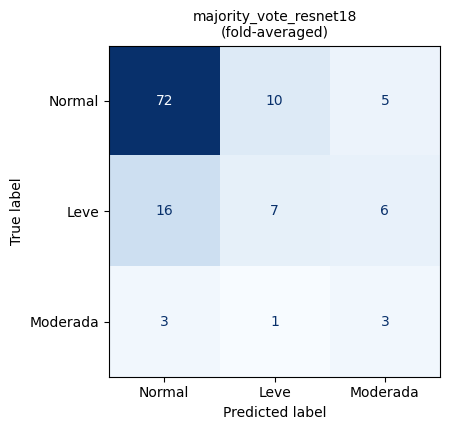

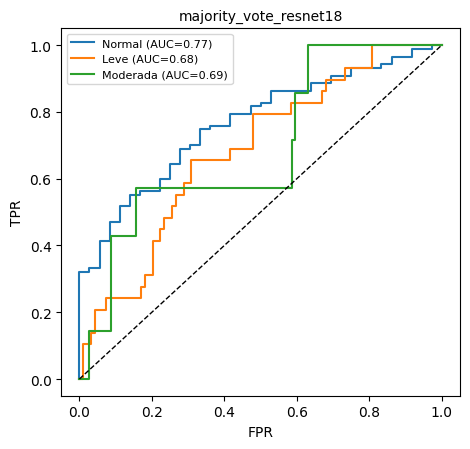

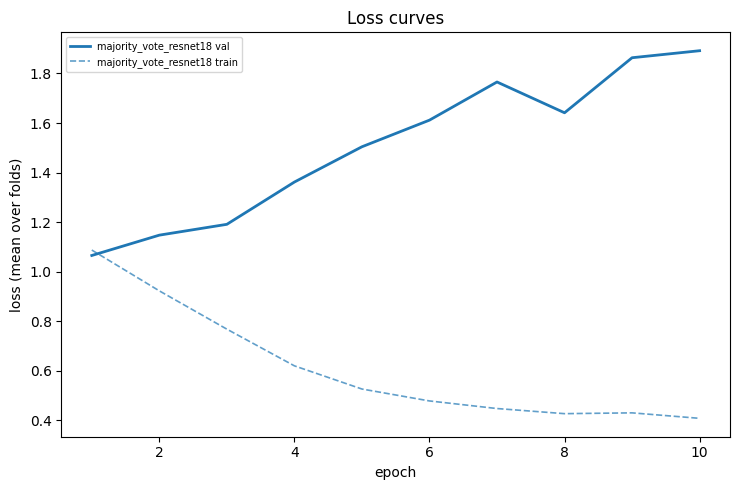

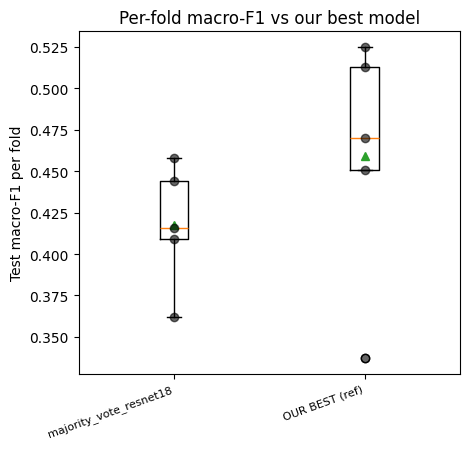

In [22]:
CLASS_NAMES = [IDX_TO_CLASS[i] for i in range(NUM_CLASSES)]
n_var = len(result_names)

fig, axes = plt.subplots(1, n_var, figsize=(4.6 * n_var, 4.4), squeeze=False)
for ax, name in zip(axes[0], result_names):
    cm = confusion_matrix(test_labels, ensemble_probs[name].argmax(1), labels=list(range(NUM_CLASSES)))
    ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(name + "\n(fold-averaged)", fontsize=10)
plt.tight_layout(); plt.savefig(os.path.join(RESULTS_DIR, "confusion_matrices_fold_averaged.png"), dpi=150, bbox_inches="tight"); plt.show()

from sklearn.metrics import roc_curve, auc as sk_auc
fig, axes = plt.subplots(1, n_var, figsize=(4.8 * n_var, 4.6), squeeze=False)
for ax, name in zip(axes[0], result_names):
    y_bin = label_binarize(test_labels, classes=list(range(NUM_CLASSES)))
    for c in range(NUM_CLASSES):
        if y_bin[:, c].sum() == 0:
            continue
        fpr, tpr, _ = roc_curve(y_bin[:, c], ensemble_probs[name][:, c])
        ax.plot(fpr, tpr, label=f"{CLASS_NAMES[c]} (AUC={sk_auc(fpr, tpr):.2f})")
    ax.plot([0, 1], [0, 1], "k--", lw=1); ax.set_title(name, fontsize=10); ax.set_xlabel("FPR"); ax.set_ylabel("TPR"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(os.path.join(RESULTS_DIR, "roc_curves_ovr_fold_averaged.png"), dpi=150, bbox_inches="tight"); plt.show()

fig, ax = plt.subplots(figsize=(7.5, 5))
for i, name in enumerate(result_names):
    if not fold_histories.get(name):
        continue
    h = pd.concat(fold_histories[name], ignore_index=True)
    col = f"C{i}"
    ax.plot(h.groupby("epoch")["val_loss"].mean(), color=col, lw=2, label=f"{name} val")
    ax.plot(h.groupby("epoch")["train_loss"].mean(), color=col, lw=1.2, ls="--", alpha=0.7, label=f"{name} train")
ax.set_xlabel("epoch"); ax.set_ylabel("loss (mean over folds)"); ax.legend(fontsize=7); ax.set_title("Loss curves")
plt.tight_layout(); plt.savefig(os.path.join(RESULTS_DIR, "loss_curves.png"), dpi=150, bbox_inches="tight"); plt.show()

fig, ax = plt.subplots(figsize=(1.8 * n_var + 3, 4.6))
data = [fold_results_df.loc[fold_results_df["variant"] == n].sort_values("fold")["f1_macro"].to_numpy() for n in result_names]
ax.boxplot(data + [REF_FOLD_F1], showmeans=True)
for i, d in enumerate(data + [REF_FOLD_F1], start=1):
    ax.scatter([i] * len(d), d, color="black", alpha=0.6, zorder=3)
ax.set_xticks(range(1, n_var + 2)); ax.set_xticklabels(result_names + ["OUR BEST (ref)"], rotation=20, ha="right", fontsize=8)
ax.set_ylabel("Test macro-F1 per fold"); ax.set_title("Per-fold macro-F1 vs our best model")
plt.tight_layout(); plt.savefig(os.path.join(RESULTS_DIR, "per_fold_f1_comparison.png"), dpi=150, bbox_inches="tight"); plt.show()

## Step 13 — Zip everything and get a download link

In [23]:
from IPython.display import FileLink, display
_rd = RESULTS_DIR.rstrip("/")
zip_base = os.path.join(RESULTS_DIR_ROOT, os.path.basename(os.path.dirname(_rd)) + "_" + os.path.basename(_rd) + "_results")
zip_path = shutil.make_archive(zip_base, "zip", RESULTS_DIR)
print("Files bundled:")
for root, _, files in os.walk(RESULTS_DIR):
    for fn in sorted(files):
        print(f"  {os.path.relpath(os.path.join(root, fn), RESULTS_DIR)}  ({os.path.getsize(os.path.join(root, fn)) / 1024:.1f} KB)")
print(f"\nZip: {zip_path}  ({os.path.getsize(zip_path) / 1048576:.1f} MB)")
display(FileLink(os.path.relpath(zip_path, os.getcwd())))

Files bundled:
  benchmark_summary.csv  (0.8 KB)
  confusion_matrices_fold_averaged.png  (29.8 KB)
  cv_fold_results.csv  (0.8 KB)
  loss_curves.png  (56.0 KB)
  majority_vote_resnet18_cv_history.csv  (4.2 KB)
  majority_vote_resnet18_fold1_model.pt  (132774.1 KB)
  majority_vote_resnet18_fold2_model.pt  (132774.1 KB)
  majority_vote_resnet18_fold3_model.pt  (132774.1 KB)
  majority_vote_resnet18_fold4_model.pt  (132774.1 KB)
  majority_vote_resnet18_fold5_model.pt  (132774.1 KB)
  per_fold_f1_comparison.png  (44.9 KB)
  roc_curves_ovr_fold_averaged.png  (43.5 KB)

Zip: /kaggle/working/benchmark_majority_vote_43_2026-10-26_results.zip  (601.5 MB)


/kaggle/working/benchmark_majority_vote_43_2026-10-26_results.zip